In [1]:
import pandas as pd

df = pd.read_csv(
    "../data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5572
Number of columns: 2


In [3]:
print(df["label"].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [6]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [7]:
df["label"].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 403


In [9]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (5169, 2)


In [10]:
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

In [11]:
df.head()

,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [12]:
df[df["label"] == "spam"]["message"].head(10)

2     Free entry in 2 a wkly comp to win FA Cup fina...
5     FreeMsg Hey there darling it's been 3 week's n...
8     WINNER!! As a valued network customer you have...
9     Had your mobile 11 months or more? U R entitle...
11    SIX chances to win CASH! From 100 to 20,000 po...
12    URGENT! You have won a 1 week FREE membership ...
15    XXXMobileMovieClub: To use your credit, click ...
19    England v Macedonia - dont miss the goals/team...
34    Thanks for your subscription to Ringtone UK yo...
42    07732584351 - Rodger Burns - MSG = We tried to...
Name: message, dtype: object

In [13]:
df[df["label"] == "ham"]["message"].head(10)

0     Go until jurong point, crazy.. Available only ...
1                         Ok lar... Joking wif u oni...
3     U dun say so early hor... U c already then say...
4     Nah I don't think he goes to usf, he lives aro...
6     Even my brother is not like to speak with me. ...
7     As per your request 'Melle Melle (Oru Minnamin...
10    I'm gonna be home soon and i don't want to tal...
13    I've been searching for the right words to tha...
14                  I HAVE A DATE ON SUNDAY WITH WILL!!
16                           Oh k...i'm watching here:)
Name: message, dtype: object

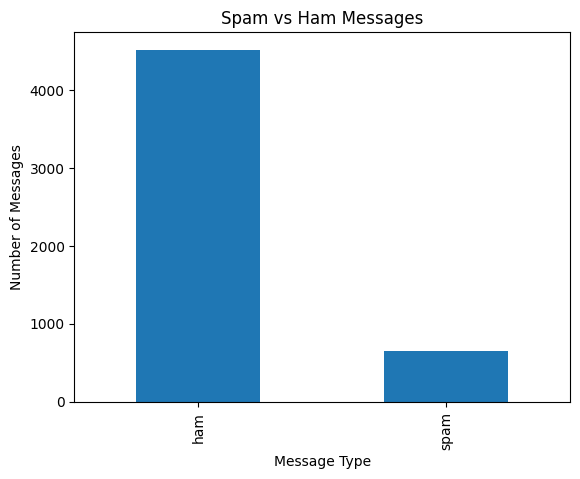

In [14]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar")

plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

In [15]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df.shape)

label        0
message      0
label_num    0
dtype: int64
Duplicate rows: 0
(5169, 3)


In [16]:
import nltk

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\patil\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [17]:
import re
from nltk.corpus import stopwords

In [18]:
stop_words = set(stopwords.words("english"))

print(list(stop_words)[:20])

['down', 'from', "mightn't", "doesn't", 'on', 'very', 'does', 'above', 'up', 'who', 'an', 'under', 'shan', 'and', 'any', "they're", "you're", 'most', 'aren', 'again']


In [19]:
def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Split into words
    words = text.split()

    # Remove stopwords
    words = [
        word for word in words
        if word not in stop_words
    ]

    # Join words back together
    return " ".join(words)

In [20]:
test_message = "Congratulations! You have won $1,000. Visit https://example.com now!"

print("Original:")
print(test_message)

print("\nCleaned:")
print(clean_text(test_message))

Original:
Congratulations! You have won $1,000. Visit https://example.com now!

Cleaned:
congratulations visit


In [21]:
df["clean_message"] = df["message"].apply(clean_text)

In [22]:
df[["message", "clean_message"]].head(10)

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling weeks word back id like fu...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile months u r entitled update latest colou...


In [23]:
X = df["clean_message"]
y = df["label_num"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5169,)
y shape: (5169,)


In [33]:
from sklearn.model_selection import train_test_split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [26]:
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [35]:
vectorizer = TfidfVectorizer(
    max_features=5000
)

In [36]:
X_train_tfidf = vectorizer.fit_transform(X_train)

In [37]:
X_test_tfidf = vectorizer.transform(X_test)

In [38]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (4135, 5000)
Testing TF-IDF shape: (1034, 5000)


In [39]:
from sklearn.naive_bayes import MultinomialNB

In [40]:
nb_model = MultinomialNB()

In [41]:
nb_model.fit(X_train_tfidf, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [42]:
nb_predictions = nb_model.predict(X_test_tfidf)

In [44]:
print(nb_predictions[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [45]:
print("Actual:")
print(y_test.values[:20])

print("\nPredicted:")
print(nb_predictions[:20])

Actual:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Predicted:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [46]:
from sklearn.metrics import accuracy_score

In [47]:
accuracy = accuracy_score(y_test, nb_predictions)

print("Naive Bayes Accuracy:",
      accuracy)

Naive Bayes Accuracy: 0.9661508704061895


In [48]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

In [49]:
precision = precision_score(
    y_test,
    nb_predictions
)

recall = recall_score(
    y_test,
    nb_predictions
)

f1 = f1_score(
    y_test,
    nb_predictions
)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 1.0
Recall: 0.732824427480916
F1 Score: 0.8458149779735683


In [50]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        nb_predictions,
        target_names=["Ham", "Spam"]
    )
)

              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.73      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



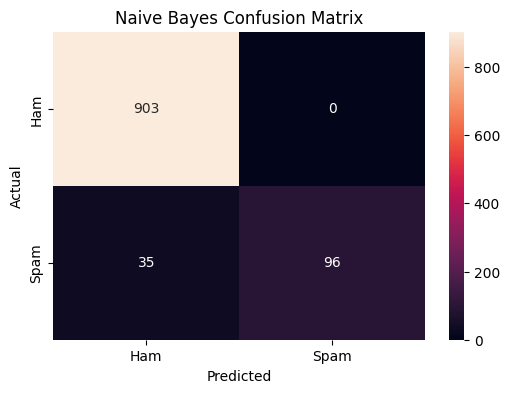

In [51]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    nb_predictions
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")

plt.show()

In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, nb_predictions)
precision = precision_score(y_test, nb_predictions)
recall = recall_score(y_test, nb_predictions)
f1 = f1_score(y_test, nb_predictions)

print("Naive Bayes Results")
print("-------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Naive Bayes Results
-------------------
Accuracy : 0.9661508704061895
Precision: 1.0
Recall   : 0.732824427480916
F1 Score : 0.8458149779735683


In [53]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    nb_predictions,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.73      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



In [54]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

In [55]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions)
lr_recall = recall_score(y_test, lr_predictions)
lr_f1 = f1_score(y_test, lr_predictions)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)

Logistic Regression Results
---------------------------
Accuracy : 0.9526112185686654
Precision: 0.9456521739130435
Recall   : 0.6641221374045801
F1 Score : 0.7802690582959642


In [56]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.95      0.99      0.97       903
        Spam       0.95      0.66      0.78       131

    accuracy                           0.95      1034
   macro avg       0.95      0.83      0.88      1034
weighted avg       0.95      0.95      0.95      1034



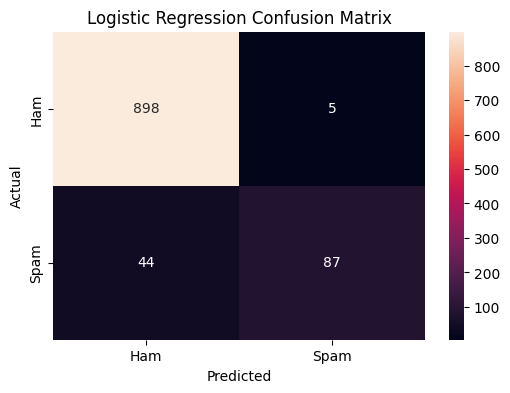

In [57]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [58]:
print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)

Logistic Regression Results
---------------------------
Accuracy : 0.9526112185686654
Precision: 0.9456521739130435
Recall   : 0.6641221374045801
F1 Score : 0.7802690582959642


In [59]:
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.95      0.99      0.97       903
        Spam       0.95      0.66      0.78       131

    accuracy                           0.95      1034
   macro avg       0.95      0.83      0.88      1034
weighted avg       0.95      0.95      0.95      1034



In [63]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(nb_model, "../models/spam_model.pkl")
joblib.dump(vectorizer, "../models/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [64]:
import os

print(os.listdir("../models"))

['spam_model.pkl', 'tfidf_vectorizer.pkl']


In [61]:
import joblib

joblib.dump(nb_model, "../models/spam_model.pkl")
joblib.dump(vectorizer, "../models/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

FileNotFoundError: [Errno 2] No such file or directory: '../models/spam_model.pkl'

In [62]:
import os

print(os.getcwd())

d:\SecondYear\Spam-Mail-Detector\notebooks


In [31]:
fit_transform(X_train)

NameError: name 'fit_transform' is not defined

In [32]:
transform(X_test)

NameError: name 'transform' is not defined